# Project Vyapaar: Business Data Treasure Hunt (Full Analysis)

**Team:** ____________________

| Member | Role |
|---|---|
| ________ | Data Analyst (cleaning) |
| ________ | Business Analyst (sales, profit, discounts, customers) |
| ________ | Operations Analyst (delivery, reviews) |
| ________ | Visualisation & Strategy (charts, hidden mystery, summary) |

**Our approach:** Explore → Question → Analyse → Verify → Visualise → Interpret → Recommend.
For every result we ask: **"So what?"**

**Data we had:** orders, products, reviews and marketing. (`customers.csv` and `delivery.csv` were not in our folder.)

**Contents:** Stage 1 Data Detective → Stage 2 Business Mystery → Stage 3 Customer & Operations → Stage 4 Hidden Mystery → Bonus Marketing → Management Summary

### How to run this notebook
**On Google Colab:**
1. Upload this notebook to Colab (File → Upload notebook).
2. Click **Runtime → Run all**.
3. When the "Choose Files" button appears, select the 4 data files: `orders.csv`, `products.csv`, `reviews.csv`, `marketing.csv`.

**On Jupyter (laptop):** keep the 4 csv files in the same folder as this notebook (or in a `data` folder next to it) and run all cells.

## Step 0: Load the data

In [1]:
import pandas as pd
import plotly.express as px
import os

# show numbers with 2 decimals and commas
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [2]:
# This small function finds a csv file whether it is in this folder or in a "data" folder
def find_file(name):
    for folder in ["", "data/", "../data/"]:
        if os.path.exists(folder + name):
            return folder + name
    return None

# If the files are not there we are probably on Google Colab, so ask to upload them
if find_file("orders.csv") is None:
    from google.colab import files
    print("Please upload orders.csv, products.csv, reviews.csv and marketing.csv")
    files.upload()

In [3]:
# encoding="utf-8-sig" removes a hidden character at the start of orders.csv and reviews.csv
orders = pd.read_csv(find_file("orders.csv"), encoding="utf-8-sig")
products = pd.read_csv(find_file("products.csv"))
marketing = pd.read_csv(find_file("marketing.csv"))

# keep_default_na=False stops pandas from turning the word "None" into a blank.
# In reviews, "None" means "no complaint", so we want to keep it.
reviews = pd.read_csv(find_file("reviews.csv"), encoding="utf-8-sig", keep_default_na=False, na_values=[""])

print("orders:", orders.shape)
print("products:", products.shape)
print("reviews:", reviews.shape)
print("marketing:", marketing.shape)

orders: (4001, 14)
products: (121, 7)
reviews: (4001, 5)
marketing: (18, 9)


---
# Stage 1: Data Detective 🔎
Before making any recommendation, we first check if we can trust the data.

### 1.1 First look

In [4]:
orders.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order
0,O00001,2025-07-23,C0538,P035,1,"1,229.10",0.10,"1,106.19","1,007.86",98.33,Store,Debit Card,NaN,South
1,O00002,2025-11-22,C0015,P011,2,"6,025.06",0.00,"12,050.12","6,266.06","5,784.06",Store,COD,NaN,South
2,O00003,2025-04-16,C0158,P039,3,"1,643.71",0.20,"3,944.90","3,353.16",591.74,Marketplace,Debit Card,M01,East
3,O00004,2025-12-10,C0456,P101,1,"3,096.04",0.15,"2,631.63","1,609.94","1,021.69",Marketplace,COD,NaN,West
4,O00005,2025-03-20,C0003,P039,2,"1,643.71",0.00,"3,287.42","2,235.44","1,051.98",Website,UPI,NaN,North


In [5]:
products.head()

,product_id,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier
0,P001,Audio Item 001,Electronics,Audio,323.17,394.11,Aruna
1,P002,Footwear Item 002,Fashion,Footwear,324.66,559.76,Futura
2,P003,Fitness Item 003,Sports,Fitness,"3,265.04","5,266.19",Futura
3,P004,Sports Accessories Item 004,Sports,Sports Accessories,525.25,847.18,Futura
4,P005,Skin Care Item 005,Beauty,Skin Care,347.35,667.98,Futura


In [6]:
reviews.head()

,review_id,order_id,rating,complaint_category,escalated
0,R00001,O00001,3.00,Late delivery,0
1,R00002,O00002,4.00,None,0
2,R00003,O00003,2.00,Late delivery,1
3,R00004,O00004,4.00,None,0
4,R00005,O00005,4.00,None,0


In [7]:
marketing.head()

,campaign_id,campaign_name,channel,start_date,end_date,spend_inr,leads,conversions,cost_per_conversion_inr
0,M01,Social Media Growth 01,Social Media,2025-01-01,2025-02-15,336420,1694,138,"2,437.83"
1,M02,Search Ads Growth 02,Search Ads,2025-01-21,2025-03-07,179161,3238,242,740.33
2,M03,Email Growth 03,Email,2025-02-10,2025-03-27,209553,2660,364,575.70
3,M04,Influencer Growth 04,Influencer,2025-03-02,2025-04-16,81295,4839,272,298.88
4,M05,Affiliate Growth 05,Affiliate,2025-03-22,2025-05-06,92961,4142,320,290.50


In [8]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4001 entries, 0 to 4000
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         4001 non-null   object 
 1   order_date       4001 non-null   object 
 2   customer_id      4000 non-null   object 
 3   product_id       4001 non-null   object 
 4   quantity         4001 non-null   int64  
 5   unit_price_inr   4001 non-null   float64
 6   discount_pct     4000 non-null   float64
 7   revenue_inr      4001 non-null   float64
 8   cost_inr         4001 non-null   float64
 9   profit_inr       4001 non-null   float64
 10  sales_channel    4001 non-null   object 
 11  payment_method   4001 non-null   object 
 12  campaign_id      2529 non-null   object 
 13  region_at_order  4001 non-null   object 
dtypes: float64(5), int64(1), object(8)
memory usage: 437.7+ KB


`order_date` is stored as text (object), not as a date. We will convert it later.

### 1.2 Missing values

In [9]:
print("ORDERS")
print(orders.isnull().sum())
print()
print("REVIEWS")
print(reviews.isnull().sum())

ORDERS
order_id              0
order_date            0
customer_id           1
product_id            0
quantity              0
unit_price_inr        0
discount_pct          1
revenue_inr           0
cost_inr              0
profit_inr            0
sales_channel         0
payment_method        0
campaign_id        1472
region_at_order       0
dtype: int64

REVIEWS
review_id             0
order_id              0
rating                1
complaint_category    0
escalated             0
dtype: int64


In [10]:
# which orders have a missing customer or discount?
orders[orders["customer_id"].isnull() | orders["discount_pct"].isnull()]

,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order
299,O00300,2025-01-05,NaN,P058,1,"3,762.37",0.05,"3,574.25","2,332.67","1,241.58",Website,COD,M16,East
777,O00778,2025-03-06,C0179,P074,1,"3,800.24",NaN,"2,660.17","2,584.16",76.01,App,Debit Card,M11,North


In [11]:
reviews[reviews["rating"].isnull()]

,review_id,order_id,rating,complaint_category,escalated
1200,R01201,O01201,NaN,Late delivery,1


**What we decided:**
- **campaign_id** is blank for 1,472 orders. That is too many to be a mistake. It just means the order did not come from a campaign, so we label it **"No campaign"**.
- **O00300** has no customer. The sale is still real, so we keep it and call the customer **"Unknown"**.
- **O00778** has no discount. We can work it out from the revenue (see 1.6).
- **R01201** has no rating. We keep the row (it still shows a late delivery and an escalation), and we do **not** make up a rating.

### 1.3 Duplicates

In [12]:
print("Duplicate rows in orders:", orders.duplicated().sum())
print("Duplicate rows in products:", products.duplicated().sum())
print("Duplicate rows in reviews:", reviews.duplicated().sum())
print("Duplicate rows in marketing:", marketing.duplicated().sum())

Duplicate rows in orders: 1
Duplicate rows in products: 1
Duplicate rows in reviews: 1
Duplicate rows in marketing: 0


In [13]:
orders[orders.duplicated(keep=False)]

,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order
500,O00501,2025-08-06,C0202,P069,1,"6,706.13",0.00,"6,706.13","3,487.19","3,218.94",Website,Credit Card,M14,South
4000,O00501,2025-08-06,C0202,P069,1,"6,706.13",0.00,"6,706.13","3,487.19","3,218.94",Website,Credit Card,M14,South


In [14]:
products[products.duplicated(keep=False)]

,product_id,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier
39,P040,Desk Accessories Item 040,Office Supplies,Desk Accessories,"3,270.76","5,031.94",DigiKart
120,P040,Desk Accessories Item 040,Office Supplies,Desk Accessories,"3,270.76","5,031.94",DigiKart


The duplicates are exact copies (same ID, same values), so they are double entries and we remove them.

⚠️ The product duplicate (**P040**) is important. If we don't remove it, every P040 order will be counted **twice** when we join the tables.

### 1.4 Spelling and category problems

In [15]:
products["category"].value_counts()

category
Beauty             25
Electronics        24
Sports             20
Home & Kitchen     20
Fashion            16
Office Supplies    15
Electronic          1
Name: count, dtype: int64

In [16]:
orders["sales_channel"].value_counts()

sales_channel
App            1346
Website        1259
Store           878
Marketplace     517
web site          1
Name: count, dtype: int64

In [17]:
products[(products["category"] == "Electronic") | (products["subcategory"] == "skin care")]

,product_id,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier
10,P011,Hair Care Item 011,Electronic,Hair Care,"3,133.03","6,025.06",Crescent
73,P074,Small Appliances Item 074,Home & Kitchen,skin care,"2,584.16","3,800.24",BharatWorks


- **P011** is called "Hair Care Item 011", but its category says "Electronic".
- **P074** is called "Small Appliances Item 074", but its subcategory says "skin care".
- "web site" is just another spelling of "Website".

To be sure about the two products, we checked the **mark-up** (list price ÷ cost). Each category seems to have its own fixed mark-up:

In [18]:
products["markup"] = products["list_price_inr"] / products["unit_cost_inr"]
products.groupby("category")["markup"].mean()

category
Beauty            1.92
Electronic        1.92
Electronics       1.22
Fashion           1.72
Home & Kitchen    1.47
Office Supplies   1.54
Sports            1.61
Name: markup, dtype: float64

In [19]:
products[products["product_id"].isin(["P011", "P074"])][["product_id", "product_name", "category", "subcategory", "markup"]]

,product_id,product_name,category,subcategory,markup
10,P011,Hair Care Item 011,Electronic,Hair Care,1.92
73,P074,Small Appliances Item 074,Home & Kitchen,skin care,1.47


P011's mark-up (1.92) matches **Beauty**, and P074's (1.47) matches **Home & Kitchen**. So the names were right and the labels were wrong:
- P011 → category = **Beauty**
- P074 → subcategory = **Small Appliances**

### 1.5 Do the money columns add up?
We re-calculated revenue ourselves: **revenue = quantity × price × (1 − discount)**

In [20]:
check = orders.copy()
check["my_revenue"] = check["quantity"] * check["unit_price_inr"] * (1 - check["discount_pct"])
check["difference"] = (check["my_revenue"] - check["revenue_inr"]).abs()

print("Orders where revenue does not match:", (check["difference"] > 1).sum())
print("Orders where profit is not revenue - cost:", ((check["revenue_inr"] - check["cost_inr"] - check["profit_inr"]).abs() > 1).sum())

Orders where revenue does not match: 0
Orders where profit is not revenue - cost: 0


Everything matches 👍 so we can trust the revenue, cost and profit numbers.

### 1.6 Working out the missing discount
Since revenue = qty × price × (1 − discount), the missing discount = **1 − revenue ÷ (qty × price)**

In [21]:
row = orders[orders["discount_pct"].isnull()]
print(1 - row["revenue_inr"] / (row["quantity"] * row["unit_price_inr"]))
print()
print("Discount levels used by the company:", sorted(orders["discount_pct"].dropna().unique().tolist()))

777   0.30
dtype: float64

Discount levels used by the company: [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4]


The answer is **0.30**, which is one of the company's normal discount levels (0, 5, 10, 15, 20, 30, 40%). So this is the real value, not a guess.

### 1.7 Strange values

In [22]:
print("Dates from", orders["order_date"].min(), "to", orders["order_date"].max())
print("Quantity from", orders["quantity"].min(), "to", orders["quantity"].max())
print("Ratings:", sorted(reviews["rating"].dropna().unique().tolist()))
print("Orders with NEGATIVE profit:", (orders["profit_inr"] < 0).sum())

Dates from 2025-01-01 to 2025-12-31
Quantity from 1 to 5
Ratings: [1.0, 2.0, 3.0, 4.0, 5.0]
Orders with NEGATIVE profit: 313


**313 orders have negative profit.** We first thought this was an error, but 1.5 showed the maths is correct. These are real sales where the discount was bigger than the margin, so it is a **business finding, not an error**. We keep them.

### 1.8 Do the tables connect?

In [23]:
print("Orders with a product that doesn't exist:", (~orders["product_id"].isin(products["product_id"])).sum())
print("Orders without a review:", (~orders["order_id"].isin(reviews["order_id"])).sum())

# we don't have customers.csv, so can we use region_at_order as the customer's region?
regions_per_customer = orders.groupby("customer_id")["region_at_order"].nunique()
print("Customers who ordered from more than 1 region:", (regions_per_customer > 1).sum())

Orders with a product that doesn't exist: 0
Orders without a review: 0


Customers who ordered from more than 1 region: 0


Every customer always orders from the **same region**, so we can use `region_at_order` as the customer's region (we did not get `customers.csv`).

### 1.9 Apply the cleaning

In [24]:
# 1. remove exact duplicate rows
orders = orders.drop_duplicates()
products = products.drop_duplicates()
reviews = reviews.drop_duplicates()

# 2. fix the 2 wrongly labelled products
products.loc[products["product_id"] == "P011", "category"] = "Beauty"
products.loc[products["product_id"] == "P074", "subcategory"] = "Small Appliances"
products = products.drop(columns="markup")

# 3. fix spelling of sales channel
orders["sales_channel"] = orders["sales_channel"].replace("web site", "Website")

# 4. fill the 1 missing discount using: discount = 1 - revenue / (quantity x price)
orders["discount_pct"] = orders["discount_pct"].fillna(
    (1 - orders["revenue_inr"] / (orders["quantity"] * orders["unit_price_inr"])).round(2))

# 5. label blanks instead of deleting them
orders["customer_id"] = orders["customer_id"].fillna("Unknown")
orders["campaign_id"] = orders["campaign_id"].fillna("No campaign")

# 6. text -> dates
orders["order_date"] = pd.to_datetime(orders["order_date"])
marketing["start_date"] = pd.to_datetime(marketing["start_date"])
marketing["end_date"] = pd.to_datetime(marketing["end_date"])

print("orders:", orders.shape, "| products:", products.shape, "| reviews:", reviews.shape)

orders: (4000, 14) | products: (120, 7) | reviews: (4000, 5)


### 1.10 Our cleaning log (Problem → Action → Reason)

| # | Problem found | Action taken | Reason |
|---|---|---|---|
| 1 | Hidden character at the start of orders.csv and reviews.csv | Read with `encoding="utf-8-sig"` | Otherwise the `order_id` column name is wrong and joins fail |
| 2 | pandas turns "None" (no complaint) into a blank | Read reviews with `keep_default_na=False` | "None" is real information: 2,640 orders had no complaint |
| 3 | Order O00501 appears twice | Removed 1 copy | Double entry, would add ₹6,706 of fake revenue |
| 4 | Review R00334 appears twice | Removed 1 copy | One review per order |
| 5 | Product P040 appears twice | Removed 1 copy before joining | Would double count all P040 orders |
| 6 | P011 "Hair Care Item" labelled "Electronic" | Changed to Beauty | Name + mark-up (1.92) match Beauty |
| 7 | P074 "Small Appliances Item" labelled "skin care" | Changed to Small Appliances | Name + mark-up (1.47) match Home & Kitchen |
| 8 | Sales channel "web site" | Changed to "Website" | Same channel, different spelling |
| 9 | O00778 missing discount | Calculated it = 0.30 | Worked out from revenue, so not a guess |
| 10 | O00300 missing customer | Kept, customer = "Unknown" | The sale is real |
| 11 | R01201 missing rating | Kept, rating left blank | We don't invent ratings |
| 12 | 1,472 orders with no campaign | Labelled "No campaign" | Blank means no campaign, not an error |
| 13 | 313 orders with negative profit | Kept | Maths is correct, caused by big discounts |
| 14 | Dates stored as text | Converted to dates | Needed for monthly / campaign analysis |
| 15 | customers.csv and delivery.csv not given to us | Used region_at_order and "Late delivery" complaints instead | Each customer always orders from one region |

### 1.11 One clean table

In [25]:
# join orders + products + reviews using the ID columns
df = orders.merge(products, on="product_id").merge(reviews, on="order_id")
df["margin_%"] = df["profit_inr"] / df["revenue_inr"] * 100

print("Clean table:", df.shape)
df.to_csv("vyapaar_clean.csv", index=False)   # on Colab you can download it from the folder icon
df.head()

Clean table: (4000, 25)


,order_id,order_date,customer_id,product_id,quantity,unit_price_inr,discount_pct,revenue_inr,cost_inr,profit_inr,sales_channel,payment_method,campaign_id,region_at_order,product_name,category,subcategory,unit_cost_inr,list_price_inr,supplier,review_id,rating,complaint_category,escalated,margin_%
0,O00001,2025-07-23,C0538,P035,1,"1,229.10",0.10,"1,106.19","1,007.86",98.33,Store,Debit Card,No campaign,South,Audio Item 035,Electronics,Audio,"1,007.86","1,229.10",Futura,R00001,3.00,Late delivery,0,8.89
1,O00002,2025-11-22,C0015,P011,2,"6,025.06",0.00,"12,050.12","6,266.06","5,784.06",Store,COD,No campaign,South,Hair Care Item 011,Beauty,Hair Care,"3,133.03","6,025.06",Crescent,R00002,4.00,None,0,48.00
2,O00003,2025-04-16,C0158,P039,3,"1,643.71",0.20,"3,944.90","3,353.16",591.74,Marketplace,Debit Card,M01,East,Small Appliances Item 039,Home & Kitchen,Small Appliances,"1,117.72","1,643.71",Aruna,R00003,2.00,Late delivery,1,15.00
3,O00004,2025-12-10,C0456,P101,1,"3,096.04",0.15,"2,631.63","1,609.94","1,021.69",Marketplace,COD,No campaign,West,Hair Care Item 101,Beauty,Hair Care,"1,609.94","3,096.04",DigiKart,R00004,4.00,None,0,38.82
4,O00005,2025-03-20,C0003,P039,2,"1,643.71",0.00,"3,287.42","2,235.44","1,051.98",Website,UPI,No campaign,North,Small Appliances Item 039,Home & Kitchen,Small Appliances,"1,117.72","1,643.71",Aruna,R00005,4.00,None,0,32.00


✅ **Stage 1 result:** after a few small fixes, the sales and money data can be trusted.

---
# Stage 2: The Business Mystery 💰
### 2.1 Big picture

In [26]:
total_revenue = df["revenue_inr"].sum()
total_profit = df["profit_inr"].sum()

print("Total revenue: ₹", round(total_revenue / 100000, 2), "lakh")
print("Total profit:  ₹", round(total_profit / 100000, 2), "lakh")
print("Profit margin:", round(total_profit / total_revenue * 100, 1), "%")

Total revenue: ₹ 175.95 lakh
Total profit:  ₹ 47.98 lakh
Profit margin: 27.3 %


### 2.2 Does high revenue mean high profit?

In [27]:
cat = df.groupby("category")[["revenue_inr", "profit_inr"]].sum()
cat["margin_%"] = cat["profit_inr"] / cat["revenue_inr"] * 100
cat["revenue_share_%"] = cat["revenue_inr"] / cat["revenue_inr"].sum() * 100
cat["profit_share_%"] = cat["profit_inr"] / cat["profit_inr"].sum() * 100
cat = cat.sort_values("revenue_inr", ascending=False)
cat

,revenue_inr,profit_inr,margin_%,revenue_share_%,profit_share_%
category,,,,,
Beauty,"5,270,516.45","2,143,754.23",40.67,29.95,44.68
Sports,"2,985,702.97","866,630.13",29.03,16.97,18.06
Home & Kitchen,"2,791,149.97","633,071.67",22.68,15.86,13.19
Electronics,"2,555,199.70","154,694.87",6.05,14.52,3.22
Office Supplies,"2,153,940.46","551,362.66",25.60,12.24,11.49
Fashion,"1,838,507.91","448,445.30",24.39,10.45,9.35


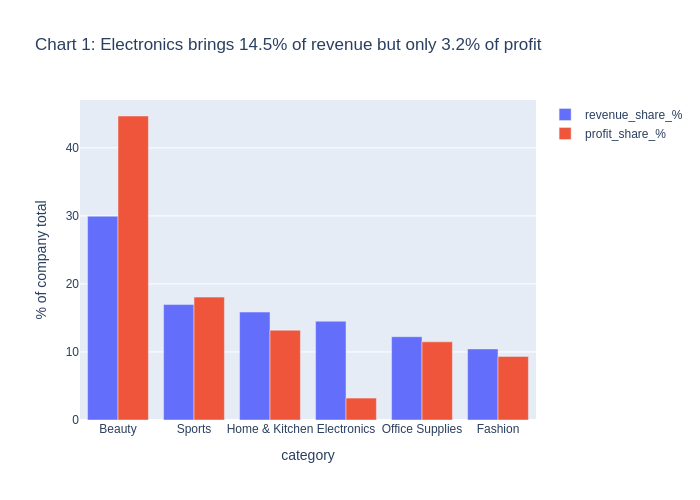

In [28]:
# CHART 1
chart1 = cat.reset_index()
fig = px.bar(chart1, x="category", y=["revenue_share_%", "profit_share_%"], barmode="group",
             title="Chart 1: Electronics brings 14.5% of revenue but only 3.2% of profit",
             labels={"value": "% of company total", "variable": ""})
fig.show()

In [29]:
# How many orders lost money in each category?
df[df["profit_inr"] < 0]["category"].value_counts()

category
Electronics        237
Sports              30
Home & Kitchen      28
Office Supplies     18
Name: count, dtype: int64

In [30]:
# Lowest margin subcategories
sub = df.groupby("subcategory")[["revenue_inr", "profit_inr"]].sum()
sub["margin_%"] = sub["profit_inr"] / sub["revenue_inr"] * 100
sub.sort_values("margin_%").head(5)

,revenue_inr,profit_inr,margin_%
subcategory,,,
Audio,"503,853.63","23,341.00",4.63
Smart Devices,"1,585,456.17","97,524.52",6.15
Mobile Accessories,"465,889.90","33,829.35",7.26
Small Appliances,"907,892.00","196,652.06",21.66
Cookware,"1,081,586.51","244,447.60",22.60


**So what?**
- **Beauty** is 30% of revenue but **45% of profit**. It is our best category.
- **Electronics** is 14.5% of revenue but only **3.2% of profit** (6.1% margin), and **237 Electronics orders lost money**.
- Why? Electronics is priced at only **1.22 × cost**, while Beauty is 1.92 × cost (see the mark-up check in Stage 1). So Electronics has very little room for discounts.

### 2.3 Are discounts helping?

In [31]:
disc = df.groupby("discount_pct").agg({"order_id": "count", "quantity": "mean", "revenue_inr": "sum", "profit_inr": "sum"})
disc.columns = ["orders", "avg_quantity", "revenue", "profit"]
disc["profit_per_order"] = disc["profit"] / disc["orders"]
disc["margin_%"] = disc["profit"] / disc["revenue"] * 100
disc

,orders,avg_quantity,revenue,profit,profit_per_order,margin_%
discount_pct,,,,,,
0.00,698,1.77,"3,562,855.47","1,336,837.67","1,915.24",37.52
0.05,633,1.75,"2,947,011.61","983,224.09","1,553.28",33.36
0.10,830,1.83,"3,985,593.04","1,181,223.87","1,423.16",29.64
0.15,548,1.79,"2,510,291.23","658,667.65","1,201.95",26.24
0.20,557,1.76,"2,258,136.82","469,981.24",843.77,20.81
0.30,444,1.78,"1,513,937.17","177,639.68",400.09,11.73
0.40,290,1.69,"817,192.12","-9,615.34",-33.16,-1.18


In [32]:
print("Correlation between discount and quantity:", round(df["discount_pct"].corr(df["quantity"]), 3))

Correlation between discount and quantity: -0.012


If discounts worked, people would buy **more units** when the discount is bigger. They don't:
- At **0%** discount people buy **1.77** units on average, and at **40%** they buy **1.69**. The correlation is almost **zero**.
- But profit per order drops from **₹1,915** to **−₹33**.

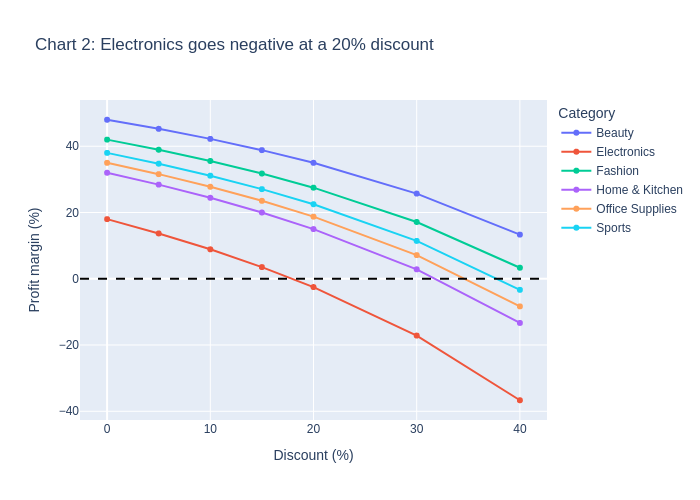

In [33]:
# CHART 2: margin at each discount level for each category
chart2 = df.pivot_table(index="discount_pct", columns="category", values="margin_%", aggfunc="mean")
chart2.index = chart2.index * 100   # 0.2 -> 20 (%)

fig = px.line(chart2, markers=True,
              title="Chart 2: Electronics goes negative at a 20% discount",
              labels={"discount_pct": "Discount (%)", "value": "Profit margin (%)", "category": "Category"})
fig.add_hline(y=0, line_dash="dash", line_color="black")
fig.show()

In [34]:
# What if Electronics discounts were capped at 10%?
# (assumption: people still buy the same quantity, which the table above supports)
elec = df[df["category"] == "Electronics"].copy()
elec["new_discount"] = elec["discount_pct"].clip(upper=0.10)
elec["new_profit"] = elec["quantity"] * elec["unit_price_inr"] * (1 - elec["new_discount"]) - elec["cost_inr"]

print("Electronics profit now: ₹", round(elec["profit_inr"].sum() / 100000, 2), "lakh")
print("With a 10% cap:         ₹", round(elec["new_profit"].sum() / 100000, 2), "lakh")

Electronics profit now: ₹ 1.55 lakh
With a 10% cap:         ₹ 3.06 lakh


In [35]:
# How much did we give away in discounts?
full_price_sales = (df["quantity"] * df["unit_price_inr"]).sum()
print("Discounts given in the year: ₹", round((full_price_sales - total_revenue) / 100000, 2), "lakh")

# Deep discounts (30% and 40%)
deep = df[df["discount_pct"] >= 0.30]
print("Orders at 30-40% discount:", len(deep), "=", round(len(deep) / len(df) * 100), "% of orders")
print("Their share of profit:", round(deep["profit_inr"].sum() / total_profit * 100, 1), "%")

Discounts given in the year: ₹ 27.99 lakh
Orders at 30-40% discount: 734 = 18 % of orders
Their share of profit: 3.5 %


In [36]:
# Which category gets the most deep discounts? (% of its orders at 30-40% off)
(deep["category"].value_counts() / df["category"].value_counts() * 100).sort_values(ascending=False)

category
Fashion           54.71
Sports            13.80
Electronics       13.60
Home & Kitchen    12.76
Beauty            11.68
Office Supplies   11.02
Name: count, dtype: float64

**So what?**
- The data **does not support** the current discount strategy. Bigger discounts don't make people buy more, they just lower our margin.
- We gave away **₹28 lakh** in discounts, more than half of our total profit (₹48 lakh).
- Orders at 30-40% off are 18% of orders but only **3.5% of profit**.
- Capping Electronics discounts at 10% would almost **double** Electronics profit (₹1.55 → ₹3.06 lakh).
- **55% of Fashion orders** are at 30-40% off, so Fashion is basically always on sale.

### 2.4 Customers
**Our definition of a high-value customer:** a customer in the **top 10% by total profit** in 2025. We use profit and not revenue, because revenue can hide loss-making orders.

In [37]:
known = df[df["customer_id"] != "Unknown"]
cust = known.groupby("customer_id").agg({"order_id": "count", "revenue_inr": "sum", "profit_inr": "sum"})
cust.columns = ["orders", "revenue", "profit"]

cutoff = cust["profit"].quantile(0.90)
high_value = cust[cust["profit"] >= cutoff]

print("Total customers:", len(cust))
print("High-value cut-off: ₹", round(cutoff), "profit")
print("High-value customers:", len(high_value))
print("Their average orders:", round(high_value["orders"].mean(), 1), "vs everyone:", round(cust["orders"].mean(), 1))
print("Their share of profit:", round(high_value["profit"].sum() / cust["profit"].sum() * 100, 1), "%")

Total customers: 599
High-value cut-off: ₹ 15161 profit
High-value customers: 60
Their average orders: 9.2 vs everyone: 6.7
Their share of profit: 23.5 %


In [38]:
print("Customers who bought more than once:", round((cust["orders"] > 1).mean() * 100, 1), "%")
print("Customers who bought 5 or more times:", round((cust["orders"] >= 5).mean() * 100, 1), "%")

Customers who bought more than once: 98.8 %
Customers who bought 5 or more times: 81.1 %


In [39]:
# When did each customer buy for the first time?
first_order = known.groupby("customer_id")["order_date"].min()
first_order.dt.quarter.value_counts().sort_index()

order_date
1    490
2     94
3     12
4      3
Name: count, dtype: int64

**So what?**
- **98.8%** of customers come back, so Vyapaar is a **repeat-customer business**. Keeping customers happy is the most important thing.
- The **60 high-value customers** order about **9 times** a year and bring **23.5% of profit**.
- **490 of 599** customers first bought in Q1. Only **15 new customers** joined in the second half of the year (Q3 + Q4). We look at this again in the marketing part.

---
# Stage 3: Customer & Operations Mystery 🚚
*We did not get `delivery.csv`, so we use the review complaint **"Late delivery"** as our sign of a delivery problem.*

### 3.1 Which complaint hurts the most?

In [40]:
comp = df.groupby("complaint_category").agg({"order_id": "count", "rating": "mean", "escalated": "mean"})
comp.columns = ["orders", "avg_rating", "escalation_rate"]
comp["escalation_rate"] = comp["escalation_rate"] * 100
comp.sort_values("orders", ascending=False)

,orders,avg_rating,escalation_rate
complaint_category,,,
None,2640,4.34,0.00
Late delivery,695,2.43,48.35
Difficult return,184,2.91,9.24
Wrong item,173,2.86,13.87
Poor quality,155,2.93,7.10
Damaged item,153,2.88,11.76


- **Late delivery** is the most common complaint (695 orders).
- It is also the worst one: average rating **2.43** and **48%** of these customers escalate. Product complaints are only escalated 7-14% of the time.

### 3.2 Where is it happening?

In [41]:
df["late_delivery"] = df["complaint_category"] == "Late delivery"

region = df.groupby("region_at_order").agg({"order_id": "count", "late_delivery": "mean", "escalated": ["mean", "sum"], "rating": "mean"})
region.columns = ["orders", "late_delivery_%", "escalation_%", "escalations", "avg_rating"]
region["late_delivery_%"] = region["late_delivery_%"] * 100
region["escalation_%"] = region["escalation_%"] * 100
region["share_of_escalations_%"] = region["escalations"] / region["escalations"].sum() * 100
region

,orders,late_delivery_%,escalation_%,escalations,avg_rating,share_of_escalations_%
region_at_order,,,,,,
East,748,38.50,25.80,193,3.23,47.54
North,915,12.35,6.34,58,3.91,14.29
South,1309,12.15,6.42,84,3.87,20.69
West,1028,13.13,6.91,71,3.89,17.49


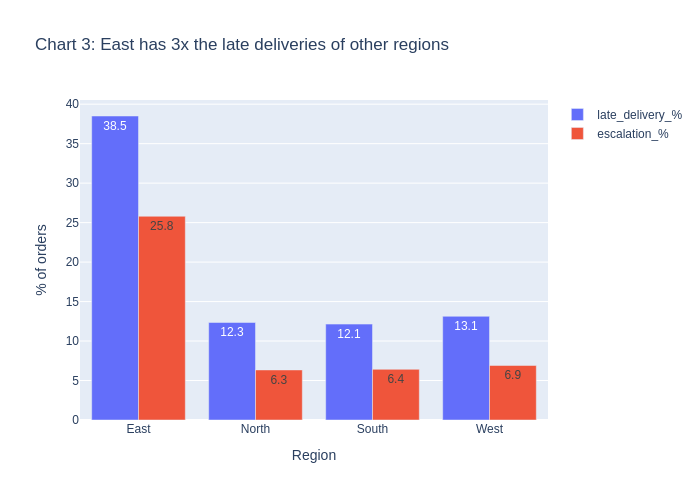

In [42]:
# CHART 3
chart3 = region.reset_index()
fig = px.bar(chart3, x="region_at_order", y=["late_delivery_%", "escalation_%"], barmode="group", text_auto=".1f",
             title="Chart 3: East has 3x the late deliveries of other regions",
             labels={"region_at_order": "Region", "value": "% of orders", "variable": ""})
fig.show()

In [43]:
# Is it just one bad month? (% late-delivery complaints by month)
df["month"] = df["order_date"].dt.month
(df.pivot_table(index="month", columns="region_at_order", values="late_delivery", aggfunc="mean") * 100).round(0)

region_at_order,East,North,South,West
month,,,,
1,42.00,13.00,15.00,18.00
2,45.00,16.00,15.00,8.00
3,40.00,10.00,13.00,13.00
4,42.00,17.00,10.00,6.00
5,27.00,10.00,8.00,25.00
6,43.00,9.00,13.00,6.00
7,39.00,14.00,13.00,6.00
8,45.00,11.00,11.00,15.00
9,35.00,9.00,12.00,20.00


In [44]:
# Is it one sales channel?
(df.pivot_table(index="region_at_order", columns="sales_channel", values="late_delivery", aggfunc="mean") * 100).round(0)

sales_channel,App,Marketplace,Store,Website
region_at_order,,,,
East,37.00,48.00,39.00,36.00
North,13.00,6.00,17.00,11.00
South,11.00,12.00,16.00,11.00
West,14.00,16.00,15.00,10.00


**What we found:**
- **38.5%** of East orders get a late-delivery complaint. In the other regions it is only **12-13%**.
- East is **19% of orders** but **48% of all escalations**, and its rating is **3.23** vs about 3.9 elsewhere.
- It is high in **every month** and **every channel**, so it is a permanent East delivery problem, not a one-time thing.

### 3.3 Do unhappy customers stop buying?

In [45]:
known = df[df["customer_id"] != "Unknown"]
per_region = known.groupby("region_at_order").agg({"order_id": "count", "customer_id": "nunique"})
per_region["orders_per_customer"] = per_region["order_id"] / per_region["customer_id"]
per_region

,order_id,customer_id,orders_per_customer
region_at_order,,,
East,747,115,6.50
North,915,133,6.88
South,1309,196,6.68
West,1028,155,6.63


In [46]:
# Small thing we noticed: Store orders also get late-delivery complaints
store = df[df["sales_channel"] == "Store"]
print("Store orders with a late-delivery complaint:", store["late_delivery"].sum(), "out of", len(store))

Store orders with a late-delivery complaint: 179 out of 878


**Honest result:** East customers still buy about **6.5 times** a year, which is close to the other regions (6.6-6.9). So with one year of data we **cannot prove** late delivery makes customers leave.

**Why it still matters:**
1. Every escalation costs customer-service time and money, and East creates almost half of them.
2. A 3.2 rating is visible to new customers on apps and marketplaces.
3. Loyal customers may stay only until a competitor delivers faster.

*Also:* 179 **Store** orders have late-delivery complaints, which is strange for an in-store purchase. We need `delivery.csv` to check this.

**Recommendation:** audit the East delivery partner and promised delivery dates, and get `delivery.csv` to find the exact cause.

---
# Stage 4: OUR HIDDEN MYSTERY 🕵️
## "Where does the money go, and is marketing worth it?"

**Question:** The orders show ₹48 lakh profit, but that ignores marketing. After paying for the 18 campaigns, how much is left? And can we prove the campaigns bring in sales?

### 4.1 Where does the money go?

In [47]:
full_price_sales = (df["quantity"] * df["unit_price_inr"]).sum()
revenue = df["revenue_inr"].sum()
discounts = full_price_sales - revenue
product_cost = df["cost_inr"].sum()
gross_profit = df["profit_inr"].sum()
marketing_spend = marketing["spend_inr"].sum()
left = gross_profit - marketing_spend

print("Sales at full price:  ₹", round(full_price_sales / 100000, 2), "lakh")
print("- Discounts:          ₹", round(discounts / 100000, 2), "lakh")
print("= Revenue:            ₹", round(revenue / 100000, 2), "lakh")
print("- Product cost:       ₹", round(product_cost / 100000, 2), "lakh")
print("= Gross profit:       ₹", round(gross_profit / 100000, 2), "lakh")
print("- Marketing spend:    ₹", round(marketing_spend / 100000, 2), "lakh")
print("= Left after marketing: ₹", round(left / 100000, 2), "lakh")
print()
print("Marketing spend as % of gross profit:", round(marketing_spend / gross_profit * 100), "%")

Sales at full price:  ₹ 203.94 lakh
- Discounts:          ₹ 27.99 lakh
= Revenue:            ₹ 175.95 lakh
- Product cost:       ₹ 127.97 lakh
= Gross profit:       ₹ 47.98 lakh
- Marketing spend:    ₹ 46.99 lakh
= Left after marketing: ₹ 0.98 lakh

Marketing spend as % of gross profit: 98 %


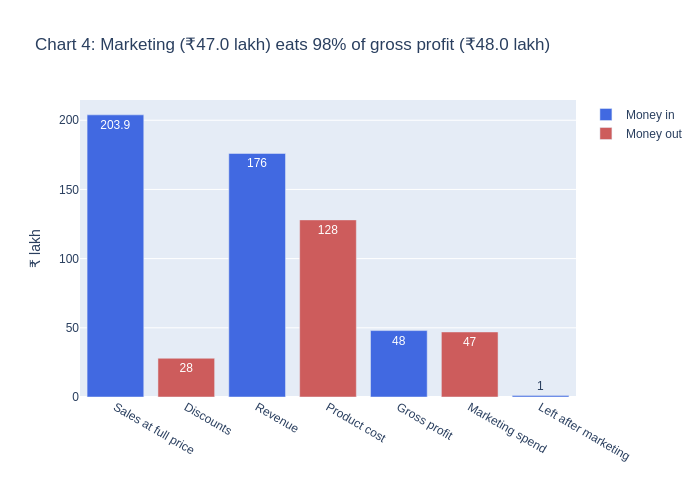

In [48]:
# CHART 4
money = pd.DataFrame({
    "step": ["Sales at full price", "Discounts", "Revenue", "Product cost", "Gross profit", "Marketing spend", "Left after marketing"],
    "lakh": [full_price_sales, discounts, revenue, product_cost, gross_profit, marketing_spend, left],
    "type": ["Money in", "Money out", "Money in", "Money out", "Money in", "Money out", "Money in"],
})
money["lakh"] = (money["lakh"] / 100000).round(1)

fig = px.bar(money, x="step", y="lakh", color="type", text_auto=True,
             category_orders={"step": list(money["step"])},   # keep the bars in our order
             color_discrete_map={"Money in": "royalblue", "Money out": "indianred"},
             title="Chart 4: Marketing (₹47.0 lakh) eats 98% of gross profit (₹48.0 lakh)",
             labels={"step": "", "lakh": "₹ lakh", "type": ""})
fig.show()

Almost **all** of the profit goes on marketing, and this is before delivery costs, salaries and rent (which we don't have). So: **is marketing actually bringing in the sales?**

### 4.2 Were "campaign orders" placed during the campaign?

In [49]:
tagged = df[df["campaign_id"] != "No campaign"]
tagged = tagged.merge(marketing[["campaign_id", "start_date", "end_date"]], on="campaign_id")

def timing(row):
    if row["order_date"] < row["start_date"]:
        return "Before campaign started"
    elif row["order_date"] > row["end_date"]:
        return "After campaign ended"
    else:
        return "During campaign"

tagged["timing"] = tagged.apply(timing, axis=1)
print(tagged["timing"].value_counts())
print()
print((tagged["timing"].value_counts(normalize=True) * 100).round(1))

timing
Before campaign started    1215
After campaign ended       1030
During campaign             283
Name: count, dtype: int64

timing
Before campaign started   48.10
After campaign ended      40.70
During campaign           11.20
Name: proportion, dtype: float64


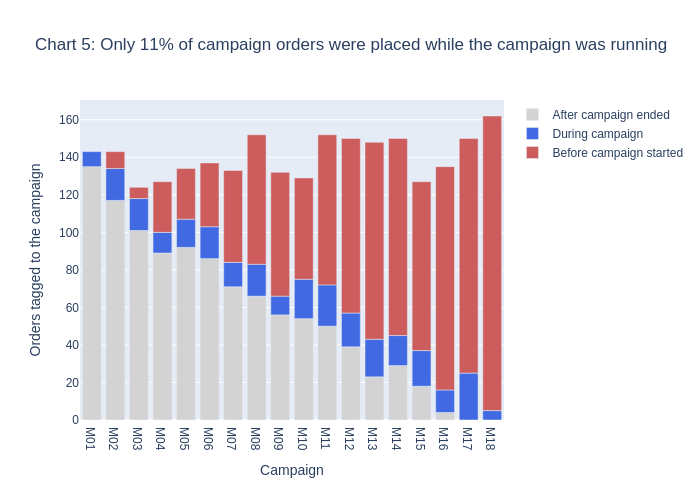

In [50]:
# CHART 5
chart5 = tagged.groupby(["campaign_id", "timing"]).size().reset_index(name="orders")
fig = px.bar(chart5, x="campaign_id", y="orders", color="timing",
             color_discrete_map={"Before campaign started": "indianred", "During campaign": "royalblue", "After campaign ended": "lightgrey"},
             title="Chart 5: Only 11% of campaign orders were placed while the campaign was running",
             labels={"campaign_id": "Campaign", "orders": "Orders tagged to the campaign", "timing": ""})
fig.show()

In [51]:
# Does a campaign that spends more get more orders?
per_campaign = tagged.groupby("campaign_id")["order_id"].count().reset_index(name="tagged_orders")
per_campaign = per_campaign.merge(marketing[["campaign_id", "channel", "spend_inr", "conversions"]], on="campaign_id")
print("Correlation between spend and tagged orders:", round(per_campaign["spend_inr"].corr(per_campaign["tagged_orders"]), 2))
per_campaign

Correlation between spend and tagged orders: 0.19


,campaign_id,tagged_orders,channel,spend_inr,conversions
0,M01,143,Social Media,336420,138
1,M02,143,Search Ads,179161,242
2,M03,124,Email,209553,364
3,M04,127,Influencer,81295,272
4,M05,134,Affiliate,92961,320
5,M06,137,Outdoor,226626,58
6,M07,133,Social Media,413129,373
7,M08,152,Search Ads,410288,118
8,M09,132,Email,340036,482
9,M10,129,Influencer,335202,346


In [52]:
# Marketing says it got this many conversions... how many customers do we have?
known = df[df["customer_id"] != "Unknown"]
first_order = known.groupby("customer_id")["order_date"].min()
h2 = marketing[marketing["start_date"] >= "2025-07-01"]

print("Conversions reported by marketing:", marketing["conversions"].sum())
print("Total customers in our orders:", known["customer_id"].nunique())
print()
print("Spend on campaigns started in Jul-Dec: ₹", round(h2["spend_inr"].sum() / 100000, 2), "lakh")
print("Conversions they reported:", h2["conversions"].sum())
print("NEW customers who first bought in Jul-Dec:", (first_order >= "2025-07-01").sum())

Conversions reported by marketing: 4309
Total customers in our orders: 599

Spend on campaigns started in Jul-Dec: ₹ 20.75 lakh
Conversions they reported: 1596
NEW customers who first bought in Jul-Dec: 15


### Evidence
1. **Marketing (₹47.0 lakh) = 98% of gross profit (₹48.0 lakh).** Less than **₹1 lakh** is left.
2. **48%** of "campaign" orders happened **before the campaign even started**, and only **11%** during it. That is impossible if the tag really means "this campaign brought the sale".
3. Spending more doesn't bring more tagged orders (correlation only 0.19).
4. Marketing reports **4,309 conversions**, but we only have **599 customers**. Campaigns in Jul-Dec spent **₹20.75 lakh**, but only **15 new customers** joined in that time.

### Why management should care
After the product itself, **marketing is the biggest cost**, and right now **nobody can prove it works**. Since almost all customers are repeat buyers, many "conversions" may be people who would have bought anyway.

*Assumptions:* we treat all campaign spend as 2025 cost (2 campaigns run a few weeks into Jan 2026), and we don't know exactly how marketing defines a "conversion".

### Recommendation
1. **Fix tracking:** one coupon code or link per campaign, and don't allow a campaign tag on an order outside the campaign dates.
2. Count a conversion only as a **new customer's first order**.
3. **Test it:** pause one channel in one region for a month and see if sales drop.
4. Cut the weakest channel first (see the Bonus below).

---
# Bonus: Marketing Mystery 📣
Here we use marketing's **own numbers** (remember the doubts above).

In [53]:
ch = marketing.groupby("channel")[["spend_inr", "leads", "conversions"]].sum()
ch["conversion_rate_%"] = ch["conversions"] / ch["leads"] * 100
ch["cost_per_conversion"] = ch["spend_inr"] / ch["conversions"]
ch["share_of_spend_%"] = ch["spend_inr"] / ch["spend_inr"].sum() * 100
ch["share_of_conversions_%"] = ch["conversions"] / ch["conversions"].sum() * 100
ch.sort_values("cost_per_conversion")

,spend_inr,leads,conversions,conversion_rate_%,cost_per_conversion,share_of_spend_%,share_of_conversions_%
channel,,,,,,,
Affiliate,604009,12709,941,7.40,641.88,12.85,21.84
Email,799396,7206,988,13.71,809.11,17.01,22.93
Influencer,729094,11986,714,5.96,"1,021.14",15.51,16.57
Social Media,1122583,13786,1045,7.58,"1,074.24",23.89,24.25
Search Ads,713260,6436,510,7.92,"1,398.55",15.18,11.84
Outdoor,731145,5720,111,1.94,"6,586.89",15.56,2.58


In [54]:
known = df[df["customer_id"] != "Unknown"]
print("Average profit per order: ₹", round(df["profit_inr"].mean()))
print("Average profit per customer per year: ₹", round(known.groupby("customer_id")["profit_inr"].sum().mean()))

Average profit per order: ₹ 1199
Average profit per customer per year: ₹ 8008


**So what?**
- **Outdoor** costs **₹6,587 per conversion**, about **10 times** Affiliate (₹642). It uses **15.6%** of the budget but brings only **2.6%** of conversions.
- **More leads ≠ success.** Influencer and Social Media bring lots of leads, but only 6-8% convert. **Email** converts the best (14%).
- ⚠️ **This is NOT ROI.** For ROI we would need the profit each campaign really caused, and 4.2 showed we can't get that from this data. We can only say that one Outdoor conversion costs more than the profit from one order (₹1,199).
- **Recommendation:** move Outdoor money to Email and Affiliate.

---
# Management Summary 🎯

### Finding 1: Electronics sells but barely makes money
- **Evidence:** 14.5% of revenue but only 3.2% of profit (6.1% margin). 237 Electronics orders lost money. It goes negative at a 20% discount. *(Chart 1, Chart 2)*
- **Implication:** we spend discounts on a category that can't afford them. Beauty (45% of profit) is the real profit engine.
- **Action:** cap Electronics discounts at **10%** (about **+₹1.5 lakh** profit a year), renegotiate supplier costs, and promote Beauty more.

### Finding 2: Big discounts don't increase sales
- **Evidence:** 1.77 units per order at 0% off vs 1.69 at 40% off. Profit per order falls from ₹1,915 to −₹33. ₹28 lakh was given away in discounts. *(Chart 2)*
- **Implication:** the discount strategy is not supported by the data.
- **Action:** set a **maximum discount per category** (no 40% discounts at all; Electronics max 10%) and test any big sale on a small group first.

### Finding 3: East has a delivery problem
- **Evidence:** 38.5% of East orders have a late-delivery complaint vs 12-13% elsewhere. East is 19% of orders but 48% of escalations, and its rating is 3.2 vs 3.9. *(Chart 3)*
- **Implication:** 99% of our customers come back, so customer experience is our biggest asset. Escalations cost money and low ratings put off new customers.
- **Action:** audit the East delivery partner within 30 days, set an on-time target for East, and get `delivery.csv` analysed.

### OUR HIDDEN MYSTERY: Marketing eats 98% of profit and we can't prove it works
- **Question:** after marketing, how much profit is left, and do campaigns really bring in sales?
- **Evidence:** ₹47.0 lakh of marketing vs ₹48.0 lakh gross profit. Only 11% of campaign orders were placed during the campaign (48% before it started). 4,309 "conversions" reported but only 599 customers. *(Chart 4, Chart 5)*
- **Implication:** our biggest controllable cost is not being measured.
- **Recommendation:** fix campaign tracking, count only new customers as conversions, test by pausing a channel, and move Outdoor money (₹6,587 per conversion) to Email/Affiliate.

### Limitations
- We did not have `customers.csv` or `delivery.csv`.
- "Profit" here = revenue − product cost only. Delivery, salaries and rent are not in the data.
- Only one year of data.